# 06 · Minería y predicción (R5)
Parte del DW que deja `03_dw` (`data/dw/covid_dw.zip`). Agrupa países por la forma de su pandemia,
pronostica casos y prueba una alerta temprana, siempre con **casos nuevos** (nunca acumulados como si fueran diarios)
y **tasas por 100.000 habitantes**.

| Historia | Sección |
|---|---|
| H6.1 · Segmentación de países (k-means) | 1 |
| H6.2 · `pronosticar(territorio, fecha_corte, horizonte=14)` | 2 |
| H6.3 · Backtesting con MAE y MAPE | 3 |
| H6.4 · `alerta(territorio, fecha)` y evaluación en Chile | 4 |
| H6.5 · Tercer modelo: Holt en escala logarítmica | 2 y 3 |
| H5.6 · P5 ¿Qué grupos de países tuvieron pandemias parecidas? | 5 |
| H5.7 · P6 ¿Se podía anticipar la ola de ómicron en Chile? | 6 |

P5 y P6 son preguntas del análisis (R4), pero van aquí porque usan la segmentación, `pronosticar` y `alerta`.

In [1]:
import sqlite3
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# El DW se sube comprimido (pesa ~130 MB): primero se descomprime
zipfile.ZipFile("../data/dw/covid_dw.zip").extractall("../data/dw")
dw = sqlite3.connect("../data/dw/covid_dw.db")

## 1 · Segmentación de países (H6.1)
**Pregunta:** ¿qué países tuvieron una pandemia con la misma *forma*? (insumo de P5).

- **Qué países:** los 157 con 1 millón de habitantes o más (`poblacion_pais` de `dim_territorio`), igual que en H2.4 y P7.
- **Qué curva:** casos nuevos por 100.000 habitantes **por semana** (lunes a domingo, `inicio_semana` de `dim_fecha`).
  Por semana y no por día, porque en 2022 muchos países informan una vez a la semana (H2.3).
  Se usa la **opción C**: suma de los acumulados del país al último día de cada semana, menos la semana anterior.
- **Normalizar:** cada curva se divide por su máximo (1 = la peor semana de ese país). Así k-means compara **cuándo**
  tuvo cada país sus olas y no **cuánto** (si no, los grupos saldrían solo por nivel de testeo: ricos arriba, pobres abajo).
- **k-means** (`sklearn.cluster.KMeans`): cada país es un punto con 163 coordenadas (una por semana); el algoritmo
  arma k grupos minimizando la distancia de cada país al promedio de su grupo (el **centroide**, que es una curva).

In [2]:
SEMANAL = """
    SELECT t.pais, d.fecha, d.inicio_semana,
           SUM(f.casos_acumulados) AS casos_acumulados,
           MAX(t.poblacion_pais)   AS poblacion
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE t.poblacion_pais >= 1000000
    GROUP BY t.pais, d.fecha
    ORDER BY t.pais, d.fecha
"""
diario = pd.read_sql(SEMANAL, dw)

# Acumulado al último día de cada semana (país × semana)
semanal = diario.groupby(["pais", "inicio_semana"])["casos_acumulados"].last().unstack()
semanal = semanal.fillna(0)            # semanas antes de que el país aparezca en los reportes: 0 casos
semanal = semanal.iloc[:, :-1]         # la última semana (6-mar-2023) tiene solo 4 días: se deja fuera

# Opción C: casos nuevos de la semana = acumulado de la semana − acumulado de la semana anterior
nuevos = semanal.diff(axis=1)
nuevos.iloc[:, 0] = semanal.iloc[:, 0]
poblacion = diario.groupby("pais")["poblacion"].max()
incidencia = nuevos.div(poblacion, axis=0) * 100_000

print("Países:", incidencia.shape[0], "· semanas:", incidencia.shape[1],
      "·", incidencia.columns[0], "→", incidencia.columns[-1])
print("Semanas con acumulado que baja (nuevos < 0):", (incidencia < 0).sum().sum(),
      "en", (incidencia < 0).any(axis=1).sum(), "países")

Países: 157 · semanas: 163 · 2020-01-20 → 2023-02-27
Semanas con acumulado que baja (nuevos < 0): 21 en 19 países


### Control
La suma de los casos semanales de Chile tiene que dar su acumulado al 5-mar-2023 (último domingo de una semana completa).

In [3]:
chile_semanas = nuevos.loc["Chile"].sum()
chile_acumulado = diario[(diario["pais"] == "Chile") & (diario["fecha"] == "2023-03-05")]["casos_acumulados"].iloc[0]
print("Chile · suma semanal:", f"{chile_semanas:,.0f}", "· acumulado 5-mar-2023:", f"{chile_acumulado:,.0f}",
      "→", "OK" if chile_semanas == chile_acumulado else "REVISAR")

Chile · suma semanal: 5,180,329 · acumulado 5-mar-2023: 5,180,329 → OK


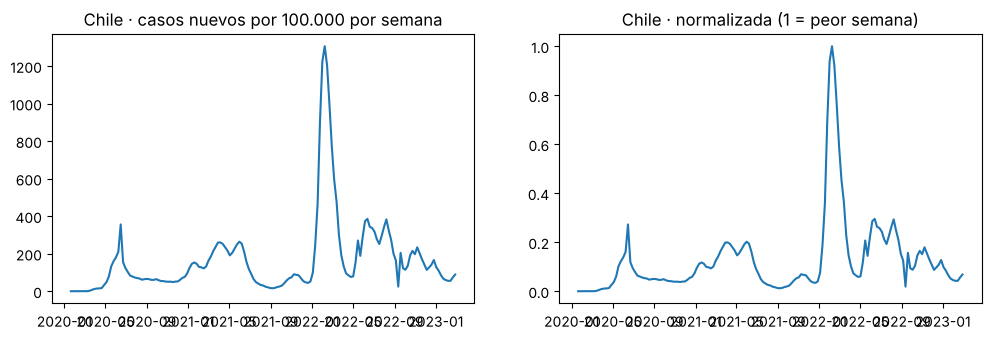

In [4]:
# Curva normalizada: cada país dividido por su peor semana (0 a 1).
# Las semanas negativas (correcciones del acumulado) se dejan en 0 solo para este cálculo: en la tabla siguen marcadas.
forma = incidencia.clip(lower=0)
forma = forma.div(forma.max(axis=1), axis=0)

# Ejemplo: la curva de Chile antes y después de normalizar
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
ejes[0].plot(pd.to_datetime(incidencia.columns), incidencia.loc["Chile"])
ejes[0].set_title("Chile · casos nuevos por 100.000 por semana")
ejes[1].plot(pd.to_datetime(forma.columns), forma.loc["Chile"])
ejes[1].set_title("Chile · normalizada (1 = peor semana)")
plt.show()

### Elegir k
Se prueba k = 2 a 8 con dos criterios vistos en clases:
- **Inercia** (suma de distancias al centroide): siempre baja al subir k; se busca el **codo**, donde deja de bajar mucho.
- **Silueta** (−1 a 1): qué tan cerca está cada país de su grupo frente al grupo vecino; más alto es mejor.

`random_state=0` y `n_init=10` para que el resultado sea el mismo en cada corrida.

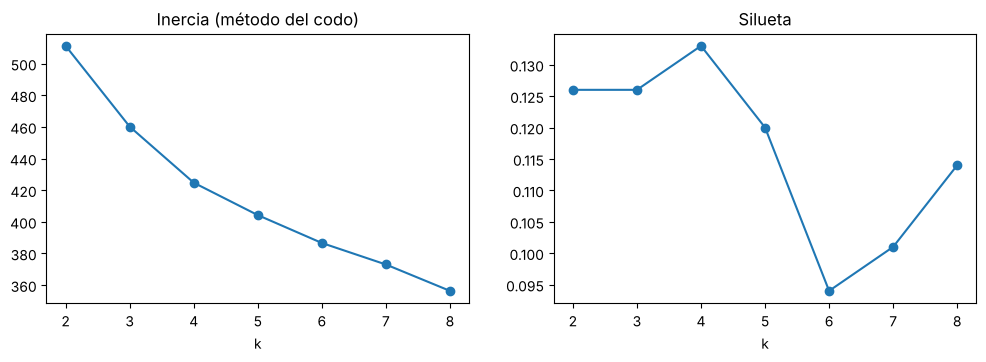

,k,inercia,silueta
0,2,511.217,0.126
1,3,460.155,0.126
2,4,424.717,0.133
3,5,404.228,0.120
4,6,386.610,0.094
5,7,373.006,0.101
6,8,356.339,0.114


In [5]:
pruebas = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=0).fit(forma)
    pruebas.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(forma, modelo.labels_)})
pruebas = pd.DataFrame(pruebas).round(3)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
ejes[0].plot(pruebas["k"], pruebas["inercia"], marker="o")
ejes[0].set_title("Inercia (método del codo)")
ejes[1].plot(pruebas["k"], pruebas["silueta"], marker="o")
ejes[1].set_title("Silueta")
for eje in ejes:
    eje.set_xlabel("k")
plt.show()
pruebas

**Decisión: k = 4.** Es la silueta más alta (0,133) y el codo de la inercia está entre 3 y 4.
Una silueta baja es normal con curvas de 163 semanas con ruido: los grupos se tocan en los bordes,
así que se leen como **tendencias**, no como fronteras exactas. Con k = 3 se mezclan los países de "cero COVID"
con los de varias olas; con k ≥ 5 aparecen grupos de 17 países que repiten formas ya vistas.

In [6]:
modelo = KMeans(n_clusters=4, n_init=10, random_state=0).fit(forma)

# El número que pone k-means a cada grupo es arbitrario: se renumeran de 1 a 4
# según qué parte de sus casos tuvieron desde 2022 (de menos a más), para que siempre salgan en el mismo orden.
desde_2022 = forma.columns >= "2022-01-01"
parte_2022 = {}
for grupo in range(4):
    paises = forma.index[modelo.labels_ == grupo]
    casos = incidencia.loc[paises].clip(lower=0)
    parte_2022[grupo] = casos.loc[:, desde_2022].values.sum() / casos.values.sum()
orden = sorted(parte_2022, key=parte_2022.get)
nuevo_numero = {grupo: i + 1 for i, grupo in enumerate(orden)}

grupos = pd.Series(modelo.labels_, index=forma.index).map(nuevo_numero).rename("grupo")
centroides = pd.DataFrame(modelo.cluster_centers_, columns=forma.columns).rename(index=nuevo_numero).sort_index()
print("Países por grupo:", grupos.value_counts().sort_index().to_dict())
print("Chile está en el grupo", grupos["Chile"])

Países por grupo: {1: 35, 2: 50, 3: 56, 4: 16}
Chile está en el grupo 3


### Características de cada grupo
Primero, cómo es la curva: en qué año cayeron sus casos, qué parte de los países tuvo su peor semana antes de ómicron
(1-dic-2021, la misma ventana de P7) y cuántas semanas pasó cerca de su máximo (más de 30 % de su peor semana:
pocas = picos cortos, muchas = olas largas o repetidas).
Después, lo que **no** entró a k-means: cuántos casos tuvo (incidencia total),
ingreso y edad (Banco Mundial, H3.3) y el índice de calidad (H2.4). Se usan medianas, porque hay países extremos.

In [7]:
atributos = pd.read_sql("""
    SELECT pais, MAX(pib_per_capita) AS pib_per_capita, MAX(pct_65_mas) AS pct_65_mas
    FROM dim_territorio WHERE nivel = 'pais' GROUP BY pais
""", dw).set_index("pais")
calidad = pd.read_parquet("../data/clean/indice_calidad_pais.parquet").set_index("country_region")["indice_calidad"]

anio = pd.to_datetime(incidencia.columns).year
peor_semana = forma.idxmax(axis=1)     # semana en que cada país tuvo su máximo
filas = []
for grupo in range(1, 5):
    paises = grupos.index[grupos == grupo]
    casos = incidencia.loc[paises].clip(lower=0)
    total = casos.values.sum()
    filas.append({
        "grupo": grupo,
        "países": len(paises),
        "% países con peor semana antes de ómicron": (peor_semana[paises] < "2021-12-01").mean() * 100,
        "semanas sobre 30 % de su peor semana (mediana)": (forma.loc[paises] > 0.3).sum(axis=1).median(),
        "% casos 2020": casos.loc[:, anio == 2020].values.sum() / total * 100,
        "% casos 2021": casos.loc[:, anio == 2021].values.sum() / total * 100,
        "% casos 2022-23": casos.loc[:, anio >= 2022].values.sum() / total * 100,
        "casos por 100.000 (mediana)": incidencia.loc[paises].sum(axis=1).median(),
        "PIB per cápita (mediana)": atributos.loc[paises, "pib_per_capita"].median(),
        "% 65+ (mediana)": atributos.loc[paises, "pct_65_mas"].median(),
        "índice calidad (mediana)": calidad.reindex(paises).median(),
    })
caracteristicas = pd.DataFrame(filas).set_index("grupo").round(1)
caracteristicas

,países,% países con peor semana antes de ómicron,semanas sobre 30 % de su peor semana (mediana),% casos 2020,% casos 2021,% casos 2022-23,casos por 100.000 (mediana),PIB per cápita (mediana),% 65+ (mediana),índice calidad (mediana)
grupo,,,,,,,,,,
1,35,54.3,22.0,19.6,55.0,25.4,3138.4,3484.4,5.5,95.4
2,50,36.0,9.0,15.5,44.2,40.3,472.2,1350.0,3.2,89.2
3,56,5.4,11.0,11.9,32.0,56.1,22981.0,13937.4,15.6,90.4
4,16,0.0,19.0,2.2,12.4,85.4,39998.7,37518.5,16.0,93.9


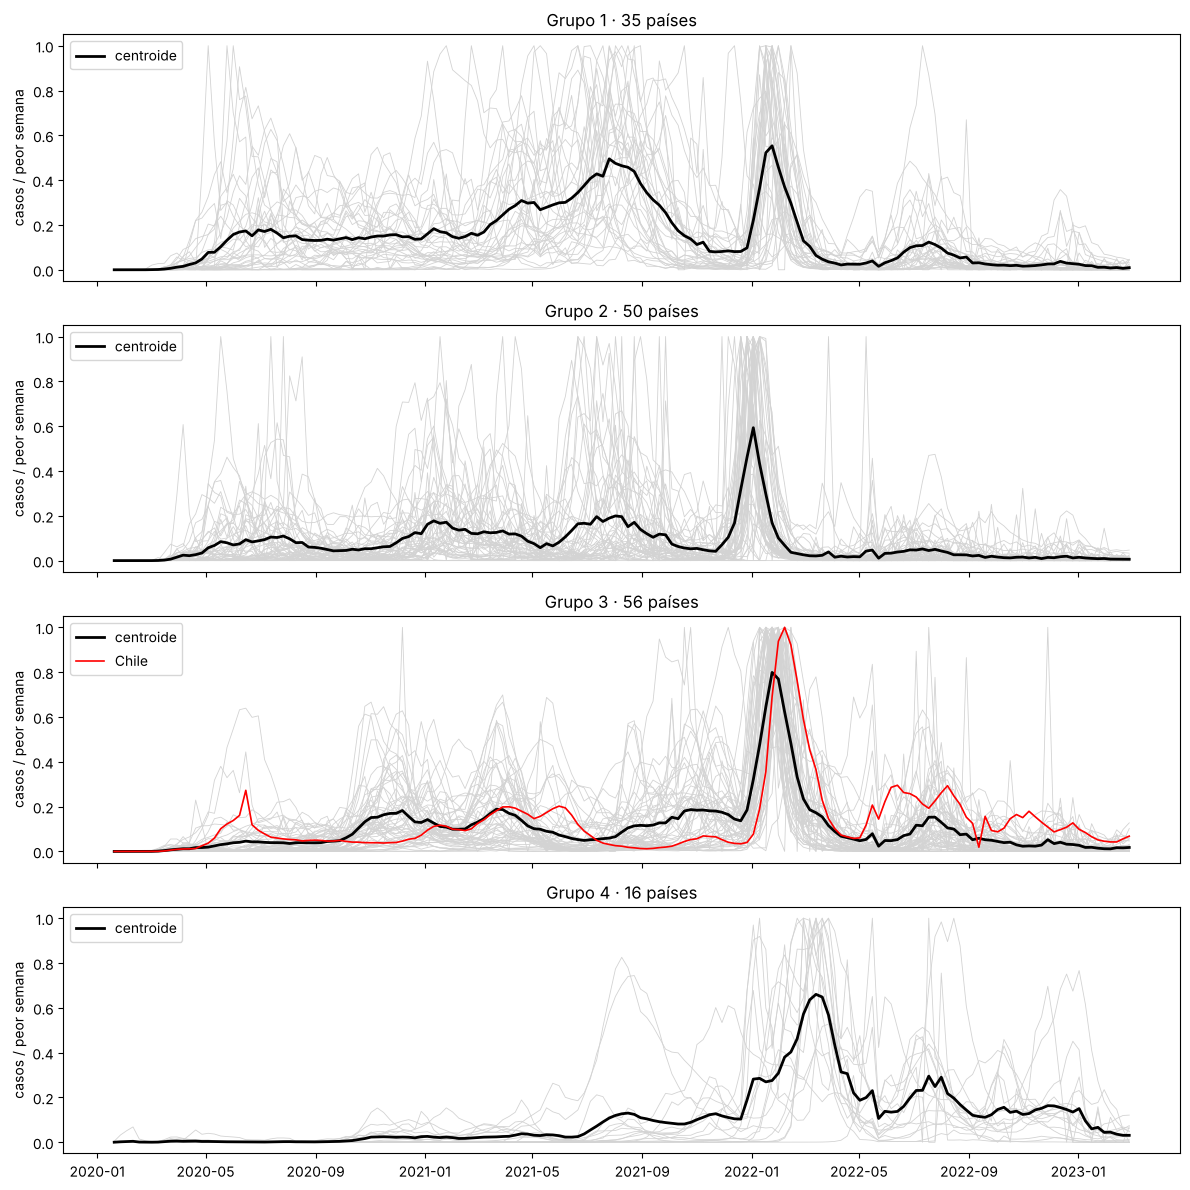

In [8]:
# Curvas normalizadas de cada grupo: países en gris, centroide en negro y Chile en rojo
fechas = pd.to_datetime(forma.columns)
fig, ejes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
for eje, grupo in zip(ejes, range(1, 5)):
    paises = grupos.index[grupos == grupo]
    for pais in paises:
        eje.plot(fechas, forma.loc[pais], color="lightgray", linewidth=0.6)
    eje.plot(fechas, centroides.loc[grupo], color="black", linewidth=2, label="centroide")
    if grupos["Chile"] == grupo:
        eje.plot(fechas, forma.loc["Chile"], color="red", linewidth=1.2, label="Chile")
    eje.set_title(f"Grupo {grupo} · {len(paises)} países")
    eje.set_ylabel("casos / peor semana")
    eje.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [9]:
# Países de cada grupo
for grupo in range(1, 5):
    print(f"Grupo {grupo} ({(grupos == grupo).sum()}):", ", ".join(grupos.index[grupos == grupo]))
    print()

Grupo 1 (35): Afghanistan, Algeria, Bangladesh, Brazil, Burma, Cambodia, Colombia, Cuba, Guatemala, Guinea-Bissau, Haiti, Honduras, India, Indonesia, Iran, Iraq, Kazakhstan, Libya, Morocco, Nepal, Nicaragua, Oman, Pakistan, Philippines, Saudi Arabia, Somalia, South Africa, Sri Lanka, Syria, Timor-Leste, Tunisia, United Arab Emirates, Uzbekistan, Venezuela, Yemen

Grupo 2 (50): Angola, Argentina, Benin, Bolivia, Botswana, Burkina Faso, Burundi, Cameroon, Canada, Central African Republic, Chad, Congo (Brazzaville), Congo (Kinshasa), Cote d'Ivoire, Dominican Republic, Equatorial Guinea, Eritrea, Eswatini, Ethiopia, Gabon, Gambia, Ghana, Guinea, Ireland, Jamaica, Kenya, Korea, North, Kyrgyzstan, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Namibia, Niger, Nigeria, Qatar, Rwanda, Senegal, Sierra Leone, South Sudan, Tajikistan, Tanzania, Togo, US, Uganda, Zambia, Zimbabwe

Grupo 3 (56): Albania, Armenia, Azerbaijan, Bahrain, Belarus, Belgium, Bosnia and Herzegovina, Bu

### Interpretación
| Grupo | Nombre | Forma de la curva | Quiénes |
|---|---|---|---|
| 1 (35) | **Olas largas en 2021** | 55 % de sus casos en 2021; la mitad (54 %) tuvo su peor semana antes de ómicron (Delta, mediados de 2021); 22 semanas cerca de su máximo | Ingreso medio-bajo y población joven (5,5 % de 65+): India, Indonesia, Irán, Brasil, Colombia, Cuba, Sudáfrica, Venezuela |
| 2 (50) | **Picos cortos y pocos casos** | Pocas semanas (9) cerca del máximo: picos aislados; mediana de 472 casos por 100.000, unas 50 veces menos que el grupo 3 | Casi toda África subsahariana: el ingreso más bajo (US\$ 1.350), la población más joven (3,2 %) y el peor índice de calidad (89,2) → probable **subregistro**: la curva muestra cuándo se testeó más que cuándo hubo contagio |
| 3 (56) | **Varias olas, la mayor en ómicron** | El 95 % tuvo su peor semana con ómicron (desde dic-2021, casi todos en ene–mar-2022), pero 44 % de sus casos fueron antes de 2022: olas previas importantes | **Chile** y casi toda Europa y Latinoamérica (Perú, Uruguay, Paraguay, Ecuador, México); población envejecida (15,6 % de 65+) |
| 4 (16) | **Contención hasta 2022** | 85 % de sus casos desde 2022: casi nada antes y después ómicron más olas posteriores (19 semanas cerca del máximo) | Asia-Pacífico de "cero COVID" o fronteras cerradas (China, Australia, Nueva Zelanda, Japón, Corea del Sur, Taiwán, Vietnam, Singapur) y Alemania, Austria, Finlandia, Grecia y Chipre; los más ricos (US\$ 37.519) y con más casos por 100.000 (40.000) |

- **Chile** queda en el **grupo 3**: su peor semana fue la del 7-feb-2022 (ómicron), con olas anteriores en 2020 y 2021.
  Qué países se le parecen más y qué significa para el Comité se responde en P5.
- El grupo 2 incluye a EE.UU., Canadá, Irlanda, Argentina y Bolivia, que no son pobres ni tienen pocos casos: entran por
  **forma**, porque su pico de ómicron fue tanto más alto que todo lo anterior que, al normalizar, el resto de la curva queda cerca de 0.
  Es el costo de agrupar por forma y no por nivel.
- **Cautelas:** la silueta es baja (0,133), así que los países del borde podrían cambiar de grupo con otro k o
  otra normalización; los casos dependen del testeo de cada país (H4.3), y la curva normalizada no dice nada de fallecidos.

## 2 · Pronóstico: `pronosticar(territorio, fecha_corte, horizonte=14)` (H6.2)
Es la función que se ejecuta en el desafío en vivo (PPT S14): el Comité da un territorio y una fecha de corte.

- **Territorio** = un país, con el nombre que tiene en el DW (`Chile`, `US`, `Korea, South`…); sirven los 196.
- **Qué se pronostica:** los casos nuevos por día de los 14 días siguientes al corte, como **media móvil de 7 días**
  (el dato diario tiene fines de semana sin informe y, en 2022, informes semanales que lo vuelven ruido).
- **Sin fuga de datos:** la primera línea deja solo los días **hasta** `fecha_corte` (`hist`) y todo lo demás usa solo `hist`.
  La media móvil mira hacia atrás (el día y los 6 anteriores), así que tampoco usa nada posterior.
- **Tres modelos:**
  - **Base:** la media móvil del día del corte, repetida 14 días ("los próximos días serán como la última semana").
  - **Holt** (suavizamiento exponencial con tendencia, `ExponentialSmoothing` de statsmodels): lleva un **nivel** y una
    **tendencia** que se actualizan día a día, dando más peso a lo reciente. La tendencia va **amortiguada**
    (`damped_trend=True`) para que una subida no se proyecte sin fin. Sus parámetros se ajustan solo con `hist`.
    Como la tendencia puede llevar el pronóstico bajo cero, los negativos se dejan en 0 (no existen casos negativos).
  - **Holt en escala logarítmica** (H6.5, "Excelente"): el mismo Holt, pero sobre el **logaritmo** de la media móvil; al final
    se vuelve con `exp`. En logaritmo, la tendencia es un **% de crecimiento diario** y no "+N casos por día", que es como crece
    una ola (exponencial). Nunca da negativos. Los días con menos de 1 caso se toman como 1 (el logaritmo de 0 no existe).

  ¿Por qué no usar la vacunación (fuente externa) como variable? Para pronosticar con ella habría que conocer su valor
  en los 14 días **futuros**: usar el real sería fuga de datos, y suponer que se queda fija no agrega información.
  Además, la vacunación cambia más los fallecidos que los casos (P3). Por eso el tercer modelo cambia la forma de la tendencia.

Primero, los casos nuevos de **todos** los países, día a día, con la opción C (igual que `serie_pais` de `05_analisis`).

In [10]:
PAISES = """
    SELECT t.pais, d.fecha,
           SUM(f.casos_acumulados) AS casos_acumulados,
           MAX(t.poblacion_pais)   AS poblacion
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    GROUP BY t.pais, d.fecha
    ORDER BY t.pais, d.fecha
"""
datos = pd.read_sql(PAISES, dw, parse_dates=["fecha"])

# Opción C: casos nuevos = acumulado del país − acumulado del día anterior (el primer día: todo el acumulado)
acumulado = datos.groupby("pais")["casos_acumulados"]
datos["casos_nuevos"] = acumulado.diff().fillna(datos["casos_acumulados"])

chile_total = datos[datos["pais"] == "Chile"]["casos_nuevos"].sum()
print("Países:", datos["pais"].nunique(), "· filas:", len(datos))
print("Control Chile · suma de nuevos:", f"{chile_total:,.0f}", "→", "OK" if chile_total == 5_192_286 else "REVISAR")

Países: 196 · filas: 214957
Control Chile · suma de nuevos: 5,192,286 → OK


### Regiones de Chile
En el desafío en vivo el Comité puede sortear **un país o una región de Chile**. Por eso `datos` suma las 16 regiones
(sin `Unknown`, que no tiene población), con su propia población de la tabla UID. La columna se sigue llamando `pais`,
pero también trae las regiones: así `pronosticar("Biobio", ...)` y `alerta("Biobio", ...)` funcionan sin cambiar las funciones.

- Las regiones existen desde el **20-may-2020**, cuando Chile pasó de informar como país a informar por región.
- Ese primer día su acumulado trae todos los casos anteriores (cambio de granularidad, H2.1): sus casos nuevos quedan
  **vacíos**, no se inventan. La media móvil empieza 7 días después.
- Los nombres son los de Johns Hopkins, sin tildes: `Biobio`, `Nuble`, `OHiggins`, `Aysen`, `Araucania`, `Los Rios`…
- En el control, las regiones suman 42 casos menos que Chile: son los casos asignados a `Unknown`, que se deja fuera.

In [11]:
REGIONES = """
    SELECT t.region_estado AS pais, d.fecha,
           f.casos_acumulados,
           t.poblacion
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE t.pais = 'Chile' AND t.nivel = 'region' AND t.region_estado <> 'Unknown'
    ORDER BY t.region_estado, d.fecha
"""
regiones = pd.read_sql(REGIONES, dw, parse_dates=["fecha"])

# Opción C por región. El primer día (20-may-2020) queda vacío: ese acumulado trae casos de antes del cambio.
regiones["casos_nuevos"] = regiones.groupby("pais")["casos_acumulados"].diff()

datos = pd.concat([datos, regiones], ignore_index=True)

# Control: las regiones suman lo mismo que Chile desde el 21-may-2020
desde = datos["fecha"] >= "2020-05-21"
suma_regiones = datos.loc[desde & datos["pais"].isin(regiones["pais"]), "casos_nuevos"].sum()
suma_chile = datos.loc[desde & (datos["pais"] == "Chile"), "casos_nuevos"].sum()
print("Regiones de Chile:", regiones["pais"].nunique(), "·", ", ".join(sorted(regiones["pais"].unique())))
print("Casos desde el 21-may-2020 · regiones:", f"{suma_regiones:,.0f}", "· Chile:", f"{suma_chile:,.0f}")

Regiones de Chile: 16 · Antofagasta, Araucania, Arica y Parinacota, Atacama, Aysen, Biobio, Coquimbo, Los Lagos, Los Rios, Magallanes, Maule, Metropolitana, Nuble, OHiggins, Tarapaca, Valparaiso
Casos desde el 21-may-2020 · regiones: 5,138,627 · Chile: 5,138,669


In [12]:
def pronosticar(territorio, fecha_corte, horizonte=14):
    """Casos nuevos por día (media móvil 7 días) de los `horizonte` días siguientes al corte, con tres modelos."""
    hist = datos[(datos["pais"] == territorio) & (datos["fecha"] <= fecha_corte)]
    # solo se usa hist: nada posterior al corte
    media_movil = hist.set_index("fecha")["casos_nuevos"].rolling(7).mean().dropna()

    base = [media_movil.iloc[-1]] * horizonte
    holt = ExponentialSmoothing(media_movil.values, trend="add", damped_trend=True).fit().forecast(horizonte)
    logaritmo = np.log(media_movil.clip(lower=1).values)
    holt_log = np.exp(ExponentialSmoothing(logaritmo, trend="add", damped_trend=True).fit().forecast(horizonte))

    fechas = pd.date_range(pd.Timestamp(fecha_corte) + pd.Timedelta(days=1), periods=horizonte)
    return pd.DataFrame({"fecha": fechas, "base": base, "holt": holt.clip(min=0), "holt_log": holt_log})

### Ejemplo: Chile con corte el 1-jun-2022
Inicio de la ola de mayo–septiembre de 2022 (H5.2). Lo ocurrido después del corte se dibuja solo para comparar:
la función no lo ve.

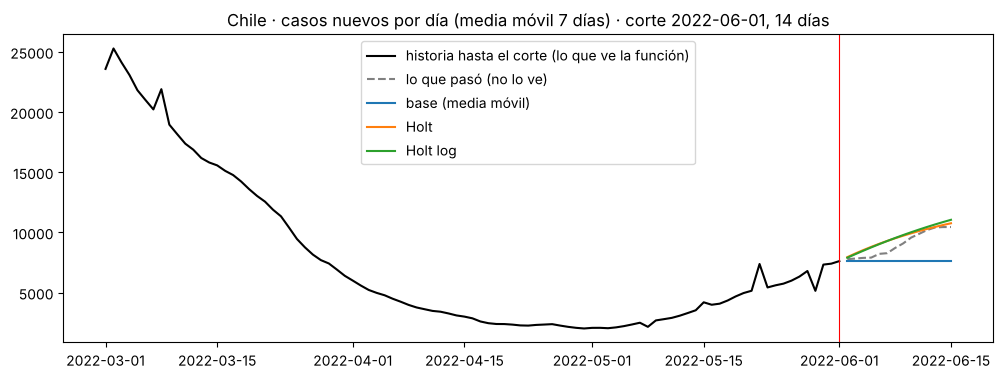

,base,holt,holt_log,real
fecha,,,,
2022-06-02,7619.0,7949.0,7900.0,7782.0
2022-06-03,7619.0,8251.0,8194.0,7832.0
2022-06-04,7619.0,8535.0,8480.0,7887.0
2022-06-05,7619.0,8803.0,8758.0,7911.0
2022-06-06,7619.0,9055.0,9028.0,8222.0
2022-06-07,7619.0,9293.0,9289.0,8279.0
2022-06-08,7619.0,9517.0,9540.0,8713.0
2022-06-09,7619.0,9729.0,9783.0,9087.0
2022-06-10,7619.0,9928.0,10017.0,9572.0


In [13]:
corte = "2022-06-01"
pronostico = pronosticar("Chile", corte)

chile = datos[datos["pais"] == "Chile"].set_index("fecha")["casos_nuevos"].rolling(7).mean()
antes = chile["2022-03-01":corte]
despues = chile.reindex(pronostico["fecha"])

plt.figure(figsize=(12, 4))
plt.plot(antes.index, antes, color="black", label="historia hasta el corte (lo que ve la función)")
plt.plot(despues.index, despues, color="gray", linestyle="--", label="lo que pasó (no lo ve)")
plt.plot(pronostico["fecha"], pronostico["base"], color="tab:blue", label="base (media móvil)")
plt.plot(pronostico["fecha"], pronostico["holt"], color="tab:orange", label="Holt")
plt.plot(pronostico["fecha"], pronostico["holt_log"], color="tab:green", label="Holt log")
plt.axvline(pd.Timestamp(corte), color="red", linewidth=0.8)
plt.title(f"Chile · casos nuevos por día (media móvil 7 días) · corte {corte}, 14 días")
plt.legend()
plt.show()

pronostico.assign(real=despues.values).set_index("fecha").round(0)

### Test: sin fuga de datos
Criterio de aceptación: el pronóstico **no cambia** si se borran los datos posteriores al corte.
Se pronostica con la tabla completa, después se borra todo lo posterior al corte, se vuelve a pronosticar y se comparan.
Se prueba en cuatro casos (tres países y una región de Chile, en distintas fechas) para no depender de uno solo.

In [14]:
casos_prueba = [("Chile", "2021-12-15"), ("US", "2022-06-01"), ("Brazil", "2021-03-15"), ("Biobio", "2021-06-01")]

datos_completos = datos
resultados = []
for pais, corte in casos_prueba:
    con_todo = pronosticar(pais, corte)
    datos = datos_completos[datos_completos["fecha"] <= corte]   # se borra todo lo posterior al corte
    sin_futuro = pronosticar(pais, corte)
    datos = datos_completos                                       # se restaura la tabla completa
    resultados.append({"país": pais, "corte": corte, "filas borradas": len(datos_completos) - (datos_completos["fecha"] <= corte).sum(),
                       "pronóstico idéntico": con_todo.equals(sin_futuro)})
pd.DataFrame(resultados)

,país,corte,filas borradas,pronóstico idéntico
0,Chile,2021-12-15,95188,True
1,US,2022-06-01,59572,True
2,Brazil,2021-03-15,153488,True
3,Biobio,2021-06-01,136952,True


**Resultado:** en los cuatro casos el pronóstico es idéntico con y sin los datos posteriores → `pronosticar` no tiene fuga.
En el ejemplo de Chile, la base se queda plana en el nivel del corte, mientras los dos Holt siguen la subida de la ola.
Cuál acierta más, y por cuánto, se mide en H6.3 (backtesting con MAE y MAPE).

## 3 · Backtesting (H6.3)
**Backtesting** = hacer como si estuviéramos en una fecha pasada: pronosticar con `pronosticar` (que solo ve hasta el corte)
y comparar con lo que de verdad pasó en los 14 días siguientes. Se compara contra la **media móvil de 7 días real**,
que es lo mismo que pronostica la función.

- **MAE** (error absoluto medio): en promedio, por cuántos casos por día se equivoca. Está en casos, así que depende del tamaño de la ola.
- **MAPE** (error porcentual absoluto medio): el mismo error como % del valor real; sirve para comparar cortes de distinto tamaño.
  Se infla cuando el valor real es chico (en los valles), por eso se miran los dos.

Se usan **8 fechas de corte en Chile**, una por fase de sus olas (H5.2), para ver cómo le va a cada modelo
en subidas, picos, bajadas y valles. Una de ellas es el 15-dic-2021, justo antes de ómicron (insumo de P6).

In [15]:
CORTES = {
    "2020-05-20": "subida ola 1",
    "2020-07-01": "bajada ola 1",
    "2021-03-15": "subida ola 2",
    "2021-07-15": "bajada ola 2",
    "2021-12-15": "valle antes de ómicron",
    "2022-01-20": "subida ómicron",
    "2022-02-07": "pico ómicron",
    "2022-10-01": "valle",
}

# Lo que pasó de verdad: media móvil de 7 días de los casos nuevos de Chile (solo para evaluar)
chile = datos[datos["pais"] == "Chile"].set_index("fecha")["casos_nuevos"].rolling(7).mean()
MODELOS = ["base", "holt", "holt_log"]


def errores(pronostico, real):
    """MAE y MAPE de cada modelo frente a lo que pasó."""
    fila = {}
    for modelo in MODELOS:
        error = (pronostico[modelo] - real).abs()
        fila[f"MAE {modelo}"] = error.mean()
        fila[f"MAPE {modelo} (%)"] = (error / real).mean() * 100
    return fila


filas = []
pronosticos = {}
for corte, fase in CORTES.items():
    pronostico = pronosticar("Chile", corte)
    real = chile.reindex(pronostico["fecha"]).values
    pronosticos[corte] = pronostico
    filas.append({"corte": corte, "fase": fase, **errores(pronostico, real)})

backtesting = pd.DataFrame(filas)
columnas_mape = [f"MAPE {modelo} (%)" for modelo in MODELOS]
backtesting["gana"] = backtesting[columnas_mape].idxmin(axis=1).str.replace("MAPE ", "").str.replace(" (%)", "")
promedio = backtesting.mean(numeric_only=True).to_frame("promedio").T
pd.concat([backtesting, promedio]).round(1)

,corte,fase,MAE base,MAPE base (%),MAE holt,MAPE holt (%),MAE holt_log,MAPE holt_log (%),gana
0,2020-05-20,subida ola 1,1216.8,29.6,333.2,7.8,218.9,5.5,holt_log
1,2020-07-01,bajada ola 1,872.1,29.8,1058.4,36.2,243.3,8.2,holt_log
2,2021-03-15,subida ola 2,837.2,13.6,832.3,13.5,448.9,7.3,holt_log
3,2021-07-15,bajada ola 2,621.5,44.3,622.6,44.4,314.3,22.2,holt_log
4,2021-12-15,valle antes de ómicron,140.4,11.4,90.5,7.3,30.3,2.2,holt_log
5,2022-01-20,subida ómicron,10395.7,46.5,8984.8,39.5,4885.9,21.1,holt_log
6,2022-02-07,pico ómicron,950.2,2.8,6318.0,18.6,6353.8,18.7,base
7,2022-10-01,valle,309.3,9.9,427.9,13.2,329.5,10.5,base
promedio,NaN,NaN,1917.9,23.5,2333.5,22.6,1603.1,12.0,NaN


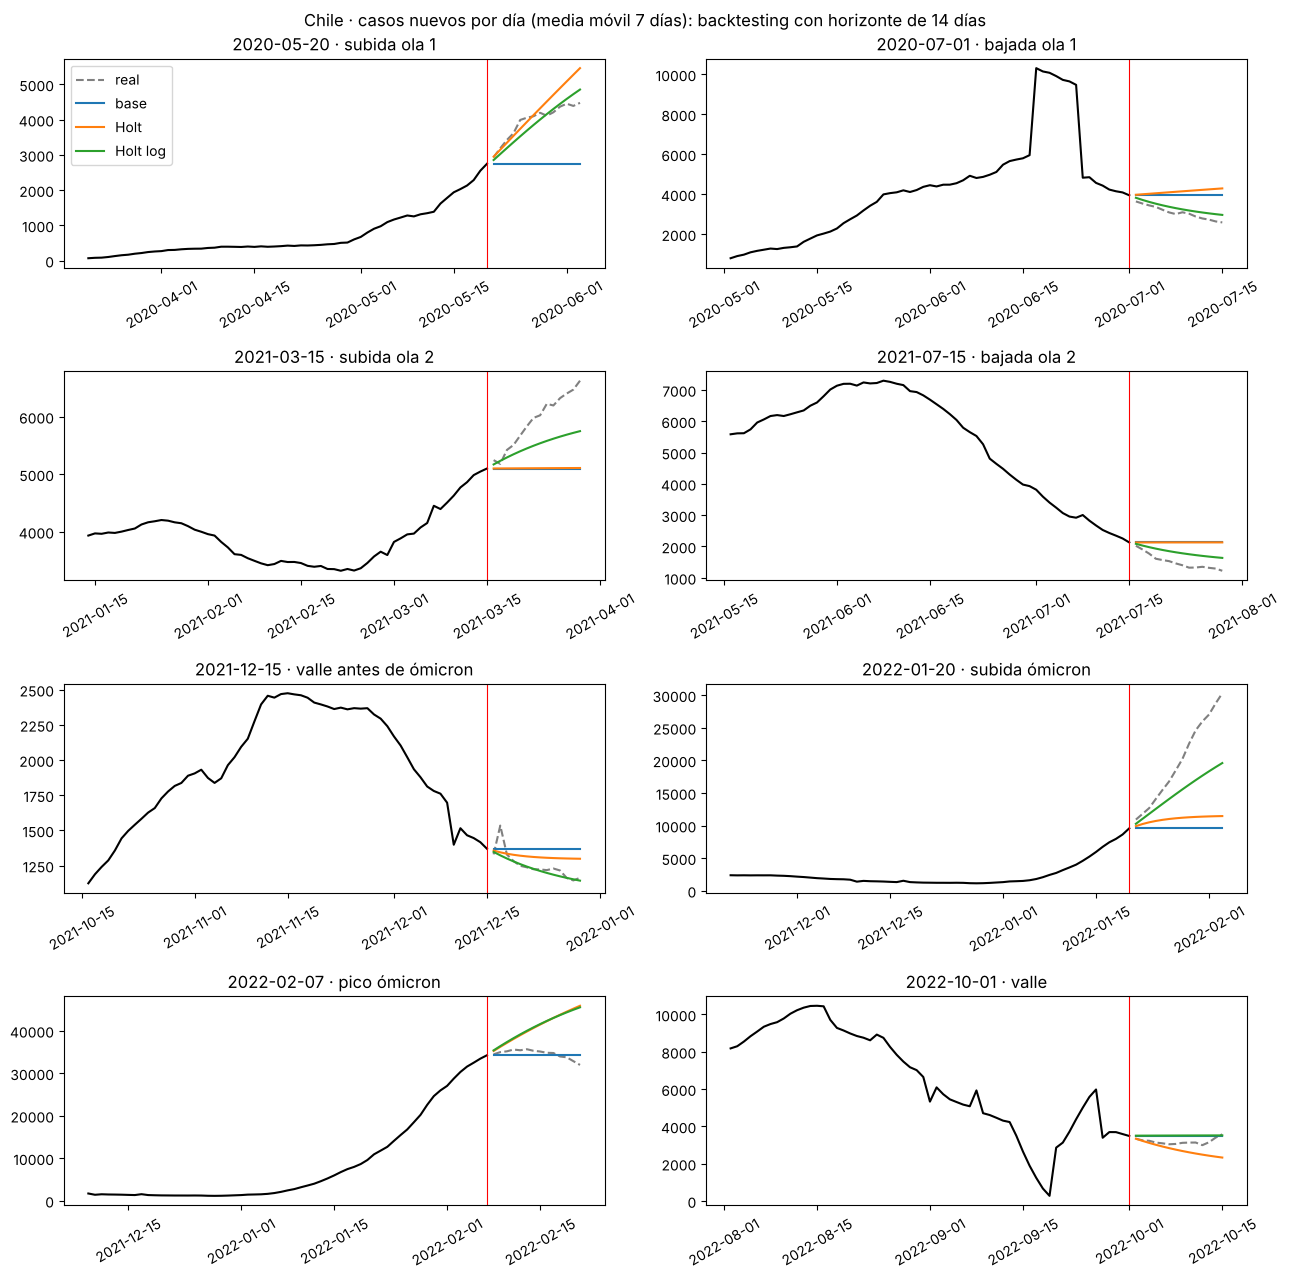

In [16]:
# Cada corte: historia de 60 días (negro), lo que pasó (gris) y los dos pronósticos
fig, ejes = plt.subplots(4, 2, figsize=(13, 13))
for eje, (corte, fase) in zip(ejes.flat, CORTES.items()):
    pronostico = pronosticos[corte]
    inicio = pd.Timestamp(corte) - pd.Timedelta(days=60)
    eje.plot(chile[inicio:corte].index, chile[inicio:corte], color="black")
    eje.plot(pronostico["fecha"], chile.reindex(pronostico["fecha"]), color="gray", linestyle="--", label="real")
    eje.plot(pronostico["fecha"], pronostico["base"], color="tab:blue", label="base")
    eje.plot(pronostico["fecha"], pronostico["holt"], color="tab:orange", label="Holt")
    eje.plot(pronostico["fecha"], pronostico["holt_log"], color="tab:green", label="Holt log")
    eje.axvline(pd.Timestamp(corte), color="red", linewidth=0.8)
    eje.set_title(f"{corte} · {fase}")
    eje.tick_params(axis="x", labelrotation=30)
ejes[0, 0].legend()
plt.suptitle("Chile · casos nuevos por día (media móvil 7 días): backtesting con horizonte de 14 días")
plt.tight_layout()
plt.show()

### Interpretación
| | base | Holt | Holt log |
|---|---|---|---|
| MAPE promedio (8 cortes) | 23,5 % | 22,6 % | **12,0 %** |
| Cortes en que es el mejor | 2 | 0 | **6** |

- **El mejor es Holt en escala logarítmica (H6.5):** gana 6 de las 8 fechas y tiene cerca de la mitad del error promedio.
  Holt normal casi no mejora a la base (tiene menos error en 4 de las 8 fechas).
- **Por qué funciona mejor en log:** una ola crece en **porcentaje** (los contagios se multiplican), y en log esa subida es una recta.
  En la subida de ómicron (20-ene-2022), donde los casos se triplican en 14 días, baja el error de 39,5 % (Holt) a 21,1 %; aun así
  queda corto. En la subida de la ola 1 (20-may-2020): 29,6 % (base) → 7,8 % (Holt) → 5,5 % (Holt log).
- **Todos fallan en los cambios de dirección:** en el **pico de ómicron** (7-feb-2022) los dos Holt siguen proyectando la subida
  (≈ 18,6 %), mientras la base, plana, acierta con 2,8 %. Ningún modelo que solo mira la propia curva "sabe" que la ola va a dar vuelta.
- **La calidad del dato pesa:** el corte del 1-jul-2020 arrastra el pico de rezago del 17-jun-2020 (36.179 casos en un día, H2.3),
  que infla la media móvil y hace que Holt proyecte subida en plena bajada (36,2 %). Holt log lo resiste mejor (8,2 %),
  porque en log ese salto pesa menos.
- **Conclusión:** para el desafío en vivo, `pronosticar` muestra los tres modelos y **Holt log es el de referencia**; cerca
  de un pico conviene mirar también la base. Para anticipar el inicio de una ola se necesita otra herramienta: la alerta de H6.4.

## 4 · Alerta temprana: `alerta(territorio, fecha)` (H6.4)
**Indicador:** la **variación semanal de la incidencia** (PPT S14): media móvil de 7 días de casos nuevos por 100.000 hoy,
comparada con la de 7 días antes.

**Regla:** la alerta se activa si la incidencia **subió `umbral` % o más en una semana** y además está sobre un **piso**
de casos por 100.000. El piso evita alarmas cuando hay tan pocos casos que cualquier subida es un porcentaje grande
(pasar de 0,2 a 0,4 por 100.000 es +100 %, pero no es una ola).

Igual que `pronosticar`, la función recibe la fecha y **solo usa los datos hasta esa fecha**.

In [18]:
def alerta(territorio, fecha, umbral=25, piso=5):
    """¿Estaba activa la alerta ese día? Incidencia (MM7 por 100.000) que sube umbral % o más en 7 días y está sobre el piso."""
    hist = datos[(datos["pais"] == territorio) & (datos["fecha"] <= fecha)]
    # solo se usa hist: nada posterior a la fecha
    incidencia = hist["casos_nuevos"].rolling(7).mean() / hist["poblacion"] * 100_000
    hoy, semana_antes = incidencia.iloc[-1], incidencia.iloc[-8]
    variacion = (hoy / semana_antes - 1) * 100
    return {"fecha": pd.Timestamp(fecha), "incidencia_100k": float(hoy), "variacion_semanal_pct": float(variacion),
            "activa": bool(variacion >= umbral and hoy >= piso)}


alerta("Chile", "2022-01-10")

{'fecha': Timestamp('2022-01-10 00:00:00'),
 'incidencia_100k': 16.5760600635528,
 'variacion_semanal_pct': 116.10483242400625,
 'activa': True}

### Las olas de Chile
Las mismas de P1 (H5.2): al menos 14 días seguidos con incidencia (MM7 por 100.000) sobre 15.

In [19]:
chile_dia = datos[datos["pais"] == "Chile"].copy()
chile_dia["incidencia_100k"] = chile_dia["casos_nuevos"].rolling(7).mean() / chile_dia["poblacion"] * 100_000
sobre = chile_dia["incidencia_100k"] > 15
tramo = (sobre != sobre.shift()).cumsum()     # cambia de número cada vez que cruza el umbral
olas = chile_dia[sobre].groupby(tramo[sobre]).agg(inicio=("fecha", "min"), fin=("fecha", "max"), dias=("fecha", "size"))
olas = olas[olas["dias"] >= 14].reset_index(drop=True)
olas.index = olas.index + 1
olas

,inicio,fin,dias
1,2020-05-21,2020-07-11,52
2,2021-01-07,2021-07-08,183
3,2022-01-10,2022-04-15,96
4,2022-05-11,2022-09-14,127
5,2022-09-21,2023-01-16,118


### Evaluación en la historia de Chile
Se calcula la alerta **día a día** (desde el 20-mar-2020, dos semanas después del primer caso) como si cada día fuera hoy.
Un **episodio** de alerta es una racha de días seguidos con la alerta activa; cada episodio se clasifica así:

- **Anticipa una ola:** empieza en los 21 días previos al inicio de una ola. Días de anticipación = inicio de la ola − inicio del episodio.
- **Dentro de una ola:** empieza con la ola ya en curso (rebrote o detección tardía). No cuenta como falsa ni como anticipación.
- **Falsa alarma:** ninguna de las dos: no vino una ola en los 21 días siguientes.

Si ninguna alerta empieza antes de una ola, pero sí durante ella, la anticipación es **negativa** (días de atraso);
si no hay alerta en toda la ola, la ola **no se detectó**.

In [20]:
fechas = chile_dia.loc[chile_dia["fecha"] >= "2020-03-20", "fecha"]
historial = pd.DataFrame([alerta("Chile", fecha) for fecha in fechas])
VENTANA = pd.Timedelta(days=21)


def evaluar(activa):
    """Días de anticipación por ola y clasificación de cada episodio de alerta (activa: serie de True/False por día)."""
    inicios = historial["fecha"][activa & ~activa.shift(fill_value=False)]   # primer día de cada episodio

    anticipacion = {}
    for numero, ola in olas.iterrows():
        antes = inicios[(inicios >= ola["inicio"] - VENTANA) & (inicios <= ola["inicio"])]
        durante = historial["fecha"][activa & (historial["fecha"] >= ola["inicio"]) & (historial["fecha"] <= ola["fin"])]
        if len(antes) > 0:
            anticipacion[numero] = (ola["inicio"] - antes.min()).days
        elif len(durante) > 0:
            anticipacion[numero] = -(durante.min() - ola["inicio"]).days
        else:
            anticipacion[numero] = None   # no se detectó

    episodios = []
    for inicio in inicios:
        if ((olas["inicio"] >= inicio) & (olas["inicio"] <= inicio + VENTANA)).any():
            tipo = "anticipa una ola"
        elif ((olas["inicio"] <= inicio) & (olas["fin"] >= inicio)).any():
            tipo = "dentro de una ola"
        else:
            tipo = "falsa alarma"
        episodios.append({"inicio": inicio, "tipo": tipo})
    return anticipacion, pd.DataFrame(episodios)


# Se prueban varios umbrales y pisos (el indicador ya está calculado: solo cambia la regla)
filas = []
for umbral in [25, 50, 100]:
    for piso in [1, 2, 5]:
        activa = (historial["variacion_semanal_pct"] >= umbral) & (historial["incidencia_100k"] >= piso)
        anticipacion, episodios = evaluar(activa)
        filas.append({
            "umbral (%)": umbral, "piso (por 100.000)": piso,
            "olas anticipadas (de 5)": sum(1 for dias in anticipacion.values() if dias is not None and dias > 0),
            "días de anticipación por ola": list(anticipacion.values()),
            "episodios": len(episodios),
            "falsas alarmas": (episodios["tipo"] == "falsa alarma").sum(),
        })
pd.DataFrame(filas)

,umbral (%),piso (por 100.000),olas anticipadas (de 5),días de anticipación por ola,episodios,falsas alarmas
0,25,1,4,"[21, 14, 7, 2, -1]",25,11
1,25,2,4,"[21, 14, 7, 2, -1]",24,10
2,25,5,4,"[17, 14, 7, 2, -1]",21,7
3,50,1,2,"[20, None, 3, -4, -2]",12,2
4,50,2,2,"[20, None, 3, -4, -2]",11,1
5,50,5,2,"[17, None, 3, -4, -2]",11,1
6,100,1,1,"[17, None, 0, None, -2]",5,1
7,100,2,1,"[17, None, 0, None, -2]",4,0
8,100,5,1,"[17, None, 0, None, -2]",4,0


**Decisión: umbral 25 % y piso 5 por 100.000** (los valores por defecto de `alerta`).
Es la combinación que anticipa más olas (4 de 5) con menos falsas alarmas entre las que anticipan 4.
Subir el umbral a 50 % baja las falsas alarmas a 1, pero la ola de 2021 (que subió lento) ya no se detecta
y otras dos se detectan tarde. Para una sala de crisis es preferible revisar algunas falsas alarmas a perder una ola.

In [21]:
activa = historial["activa"]
anticipacion, episodios = evaluar(activa)

detalle = olas.copy()
detalle["días de anticipación"] = pd.Series(anticipacion)
detalle["primera alerta"] = detalle["inicio"] - pd.to_timedelta(detalle["días de anticipación"], unit="D")
print("Días con alerta activa:", activa.sum(), "de", len(activa))
print("Episodios:", episodios["tipo"].value_counts().to_dict())
detalle[["inicio", "fin", "primera alerta", "días de anticipación"]]

Días con alerta activa: 154 de 1085
Episodios: {'dentro de una ola': 8, 'falsa alarma': 7, 'anticipa una ola': 6}


,inicio,fin,primera alerta,días de anticipación
1,2020-05-21,2020-07-11,2020-05-04,17
2,2021-01-07,2021-07-08,2020-12-24,14
3,2022-01-10,2022-04-15,2022-01-03,7
4,2022-05-11,2022-09-14,2022-05-09,2
5,2022-09-21,2023-01-16,2022-09-22,-1


In [22]:
# Falsas alarmas: cuándo empezaron
episodios[episodios["tipo"] == "falsa alarma"]

,inicio,tipo
2,2020-07-27,falsa alarma
3,2020-07-29,falsa alarma
4,2020-10-01,falsa alarma
9,2021-10-15,falsa alarma
10,2021-11-11,falsa alarma
19,2023-02-24,falsa alarma
20,2023-03-07,falsa alarma


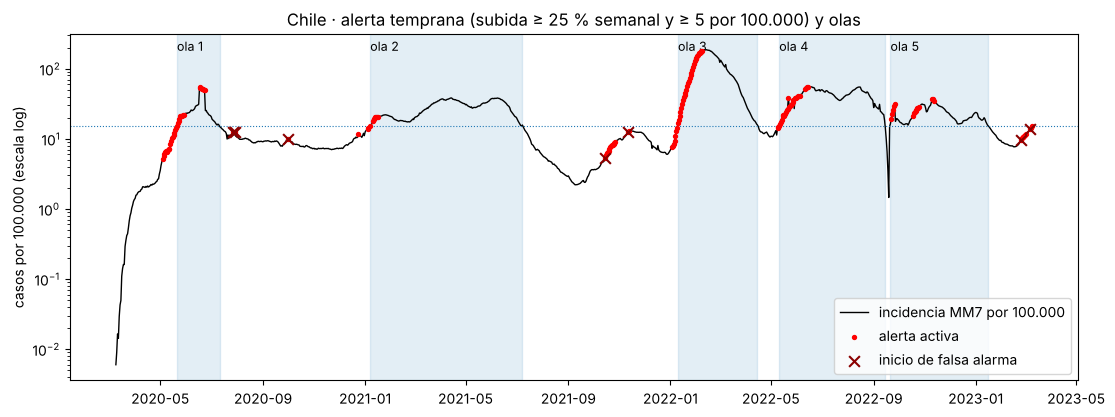

In [23]:
# Incidencia de Chile con las olas (sombra) y los días con alerta activa (rojo)
fig, eje = plt.subplots(figsize=(13, 4.5))
eje.plot(chile_dia["fecha"], chile_dia["incidencia_100k"], color="black", linewidth=1, label="incidencia MM7 por 100.000")
for numero, ola in olas.iterrows():
    eje.axvspan(ola["inicio"], ola["fin"], color="tab:blue", alpha=0.12)
    eje.text(ola["inicio"], eje.get_ylim()[1] * 0.92, f"ola {numero}", fontsize=9)
dias_alerta = historial[activa]
eje.scatter(dias_alerta["fecha"], dias_alerta["incidencia_100k"], color="red", s=8, zorder=3, label="alerta activa")
falsas = episodios[episodios["tipo"] == "falsa alarma"]["inicio"]
eje.scatter(falsas, historial.set_index("fecha").loc[falsas, "incidencia_100k"], marker="x", color="darkred", s=60,
            zorder=4, label="inicio de falsa alarma")
eje.axhline(15, color="tab:blue", linestyle=":", linewidth=0.8)
eje.set_yscale("log")
eje.set_ylabel("casos por 100.000 (escala log)")
eje.set_title("Chile · alerta temprana (subida ≥ 25 % semanal y ≥ 5 por 100.000) y olas")
eje.legend(loc="lower right")
plt.show()

### Interpretación
- **Anticipó 4 de las 5 olas**: la ola 1 con **17 días**, la ola 2 (2021) con **14**, ómicron con **7** y la de mayo de 2022 con **2**.
  Para ómicron, la alerta se activó el 3-ene-2022, una semana antes de que la incidencia pasara de 15 por 100.000.
- **La ola 5 se detectó 1 día tarde**, pero no es una ola nueva: del 14 al 19-sep-2022 (Fiestas Patrias) Chile no informó casos,
  la media móvil cayó casi a 0 y la ola de 2022 quedó partida en dos. Es un problema de calidad del dato (días sin reporte, H2.3),
  no una falla de la alerta.
- **7 falsas alarmas en 3 años** (7 de 21 episodios). No son ruido puro: las de oct–nov-2021 son una subida real
  que se quedó justo bajo el umbral de ola (≈ 13 por 100.000) y fue la antesala de ómicron; las de jul-2020 vienen
  después del pico de rezago del 17-jun-2020; las de feb–mar-2023 son el final de la serie.
- **El umbral es un compromiso:** con 50 % casi no hay falsas alarmas (1), pero la ola 2 no se detecta y dos se detectan tarde.
  Por eso se deja 25 %: la alerta es una señal para mirar con más cuidado, no una decisión automática.
- **Cautelas:** la alerta mira casos, que dependen del testeo; se calibró con la historia de Chile (en otro país el umbral
  podría ser otro); y una ventana de 21 días para "anticipar" es una elección nuestra.

## 5 · P5 · ¿Qué grupos de países tuvieron pandemias parecidas? (H5.6)
Se responde con la segmentación de la sección 1 (k-means, k = 4, sobre la forma de la curva semanal de casos).
Aquí se agrega lo que el Comité necesita para leerla: **cuántos fallecidos** tuvo cada grupo (k-means no los usó),
**dónde está Chile**, **qué países se le parecen más** y **dónde quedó Sudamérica**.

In [24]:
NOMBRES = {1: "Olas largas en 2021", 2: "Picos cortos y pocos casos",
           3: "Varias olas, la mayor en ómicron", 4: "Contención hasta 2022"}

# Fallecidos por 100.000 al 9-mar-2023 (acumulado final del país, opción C)
fallecidos = pd.read_sql("""
    SELECT t.pais, SUM(f.fallecidos_acumulados) AS fallecidos, MAX(t.poblacion_pais) AS poblacion
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE d.fecha = '2023-03-09' AND t.poblacion_pais >= 1000000
    GROUP BY t.pais
""", dw).set_index("pais")
fallecidos_100k = fallecidos["fallecidos"] / fallecidos["poblacion"] * 100_000

p5 = caracteristicas[["países", "casos por 100.000 (mediana)", "PIB per cápita (mediana)", "% 65+ (mediana)"]].copy()
p5.insert(0, "nombre", p5.index.map(NOMBRES))
p5["fallecidos por 100.000 (mediana)"] = [fallecidos_100k.reindex(grupos.index[grupos == g]).median() for g in p5.index]
p5.round(1)

,nombre,países,casos por 100.000 (mediana),PIB per cápita (mediana),% 65+ (mediana),fallecidos por 100.000 (mediana)
grupo,,,,,,
1,Olas largas en 2021,35,3138.4,3484.4,5.5,38.5
2,Picos cortos y pocos casos,50,472.2,1350.0,3.2,7.3
3,"Varias olas, la mayor en ómicron",56,22981.0,13937.4,15.6,245.1
4,Contención hasta 2022,16,39998.7,37518.5,16.0,70.3


In [25]:
# Los 10 países con la curva más parecida a la de Chile (distancia entre curvas normalizadas, la misma que usa k-means)
distancia = ((forma - forma.loc["Chile"]) ** 2).sum(axis=1) ** 0.5
parecidos = distancia.drop("Chile").sort_values().head(10).to_frame("distancia a Chile")
parecidos["grupo"] = grupos[parecidos.index]
parecidos["casos por 100.000"] = incidencia.loc[parecidos.index].sum(axis=1)
parecidos["fallecidos por 100.000"] = fallecidos_100k[parecidos.index]
print("Chile: grupo", grupos["Chile"], "·", NOMBRES[grupos["Chile"]],
      "· casos por 100.000:", f"{incidencia.loc['Chile'].sum():,.0f}", "· fallecidos por 100.000:", f"{fallecidos_100k['Chile']:,.1f}")
parecidos.round(2)

Chile: grupo 3 · Varias olas, la mayor en ómicron · casos por 100.000: 27,099 · fallecidos por 100.000: 336.2


,distancia a Chile,grupo,casos por 100.000,fallecidos por 100.000
pais,,,,
Bahrain,1.14,3,41680.60,91.27
Latvia,1.20,3,51749.23,332.36
Russia,1.31,3,15095.70,266.20
Estonia,1.32,3,46370.89,222.08
Lithuania,1.40,3,47986.31,352.50
Netherlands,1.50,3,50837.24,138.36
Norway,1.56,3,27286.35,96.16
Denmark,1.63,3,59109.30,142.96
Austria,1.64,4,65963.48,243.94


In [26]:
# Sudamérica (los 10 países de P1): grupo de cada uno
SUDAMERICA = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia",
              "Ecuador", "Paraguay", "Peru", "Uruguay", "Venezuela"]
sudamerica = pd.DataFrame({"grupo": grupos[SUDAMERICA]})
sudamerica["nombre"] = sudamerica["grupo"].map(NOMBRES)
sudamerica["casos por 100.000"] = incidencia.loc[SUDAMERICA].sum(axis=1).round(0)
sudamerica["fallecidos por 100.000"] = fallecidos_100k[SUDAMERICA].round(1)
sudamerica.sort_values("grupo")

,grupo,nombre,casos por 100.000,fallecidos por 100.000
pais,,,,
Brazil,1,Olas largas en 2021,17445.0,329.0
Colombia,1,Olas largas en 2021,12496.0,279.7
Venezuela,1,Olas largas en 2021,1941.0,20.6
Bolivia,2,Picos cortos y pocos casos,10228.0,191.6
Argentina,2,Picos cortos y pocos casos,22224.0,288.7
Chile,3,"Varias olas, la mayor en ómicron",27099.0,336.2
Paraguay,3,"Varias olas, la mayor en ómicron",11334.0,278.7
Ecuador,3,"Varias olas, la mayor en ómicron",5992.0,204.1
Peru,3,"Varias olas, la mayor en ómicron",13608.0,665.8


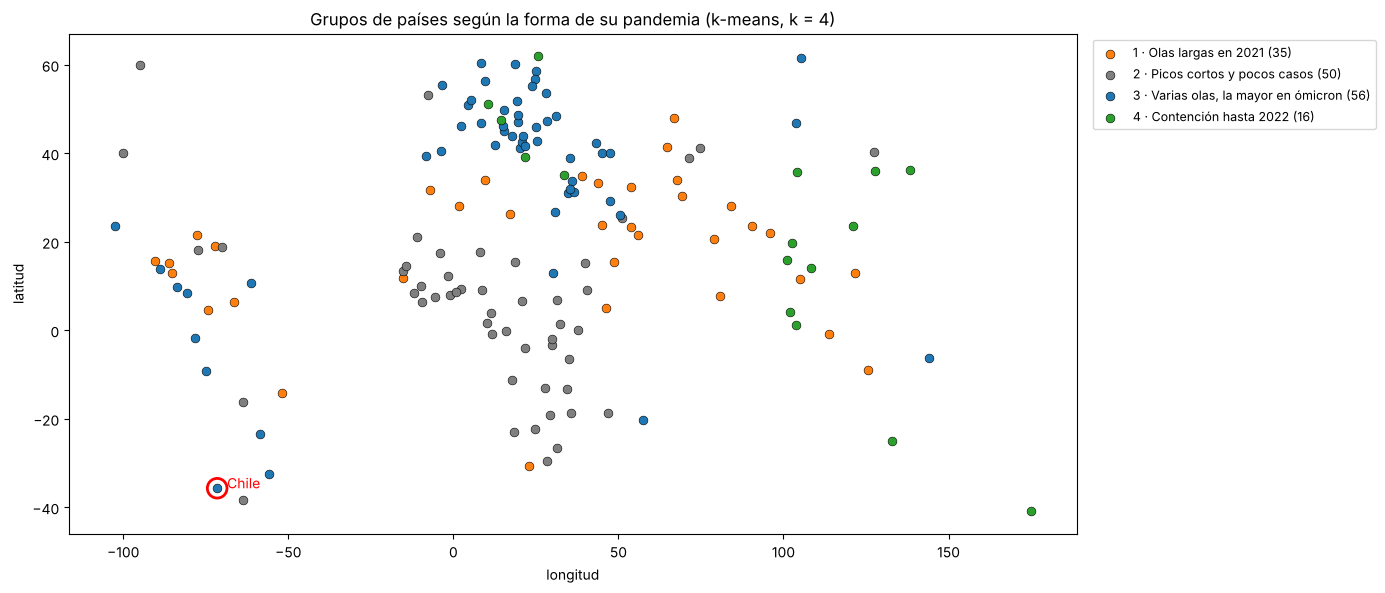

In [27]:
# Mapa: cada país en su latitud/longitud (tabla UID), coloreado por grupo
ubicacion = pd.read_sql("SELECT pais, lat, long FROM dim_territorio WHERE nivel = 'pais'", dw).set_index("pais")
mapa = ubicacion.loc[grupos.index].assign(grupo=grupos)

fig, eje = plt.subplots(figsize=(13, 6.5))
for grupo, color in zip(range(1, 5), ["tab:orange", "tab:gray", "tab:blue", "tab:green"]):
    puntos = mapa[mapa["grupo"] == grupo]
    eje.scatter(puntos["long"], puntos["lat"], color=color, s=40, edgecolor="black", linewidth=0.4,
                label=f"{grupo} · {NOMBRES[grupo]} ({len(puntos)})")
eje.scatter(mapa.loc["Chile", "long"], mapa.loc["Chile", "lat"], s=200, facecolor="none", edgecolor="red", linewidth=2)
eje.text(mapa.loc["Chile", "long"] + 3, mapa.loc["Chile", "lat"], "Chile", color="red")
eje.set_xlabel("longitud")
eje.set_ylabel("latitud")
eje.set_title("Grupos de países según la forma de su pandemia (k-means, k = 4)")
eje.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

### Respuesta P5
- **Hay 4 tipos de pandemia** (tabla de arriba). Lo más importante para el Comité: aunque k-means solo vio la forma
  de los **casos**, los grupos también separan los **fallecidos**:
  - **Varias olas, la mayor en ómicron** (56 países): mediana de **245 fallecidos por 100.000**, la más alta lejos.
    Tuvieron olas grandes en 2020–2021, antes o durante la vacunación.
  - **Contención hasta 2022** (16): la mayor cantidad de casos (40.000 por 100.000), pero **70 fallecidos por 100.000**.
    Su gran ola llegó con la población ya vacunada y con ómicron.
  - **Olas largas en 2021** (35): 38,5; **picos cortos y pocos casos** (50): 7,3, que probablemente es subregistro (poco testeo).
- **Chile está en el grupo 3** ("varias olas, la mayor en ómicron") con 336 fallecidos por 100.000, sobre la mediana de su grupo.
  Las curvas más parecidas a la suya son de **Europa (sobre todo del norte y del este) y Medio Oriente** (Baréin, Letonia, Rusia, Estonia, Lituania,
  Países Bajos, Noruega, Dinamarca, Austria, Jordania), no de sus vecinos.
- **Sudamérica quedó repartida en 3 grupos:** Brasil, Colombia y Venezuela tuvieron su peor momento en 2021 (grupo 1);
  Argentina y Bolivia entran en el grupo 2 por forma (su pico de ómicron aplasta lo anterior, no porque tengan pocos casos);
  Chile, Perú, Uruguay, Paraguay y Ecuador están en el grupo 3. Perú es el de más fallecidos (666 por 100.000).
- **Lectura:** los países que retrasaron su gran ola hasta 2022 tuvieron muchos más casos que fallecidos; es coherente con P3 y P7
  (la letalidad cae con ómicron y con la vacunación), pero sigue siendo una asociación: esos países también son los más ricos.

## 6 · P6 · ¿Se podía anticipar la ola de ómicron en Chile? (H5.7)
La ola de ómicron en Chile empezó el **10-ene-2022** (incidencia sobre 15 por 100.000, sección 4) y tuvo su peor semana
el 7-feb-2022. Se responde con tres miradas, todas **sin datos posteriores al corte**:

1. **Pronóstico** con `pronosticar` y corte en diciembre de 2021 (como pide la PPT), frente a lo que pasó.
2. **Alerta** de la sección 4: cuándo se habría activado en Chile.
3. **Alerta en otros países:** ómicron llegó a otros países antes que a Chile. ¿Lo mostraban los datos que ya teníamos en el DW?

In [28]:
# 1 · Pronóstico con corte en diciembre de 2021, a 14 días (como en el desafío) frente a lo que pasó
filas = []
for corte in ["2021-12-01", "2021-12-15", "2021-12-31"]:
    pronostico = pronosticar("Chile", corte)
    real = chile.reindex(pronostico["fecha"]).values
    ultimo = pronostico.iloc[-1]
    filas.append({"corte": corte, "día 14": ultimo["fecha"].date(), "real día 14": real[-1],
                  "base día 14": ultimo["base"], "Holt día 14": ultimo["holt"], "Holt log día 14": ultimo["holt_log"],
                  **errores(pronostico, real)})
pd.DataFrame(filas).set_index("corte").round(1)

,día 14,real día 14,base día 14,Holt día 14,Holt log día 14,MAE base,MAPE base (%),MAE holt,MAPE holt (%),MAE holt_log,MAPE holt_log (%)
corte,,,,,,,,,,,
2021-12-01,2021-12-15,1369.3,2167.9,2091.6,1980.7,482.6,31.3,425.6,27.7,372.4,24.1
2021-12-15,2021-12-29,1163.0,1369.3,1298.3,1142.7,140.4,11.4,90.5,7.3,30.3,2.2
2021-12-31,2022-01-14,5241.9,1266.1,1307.2,1330.4,1375.4,41.4,1345.1,40.2,1343.5,40.3


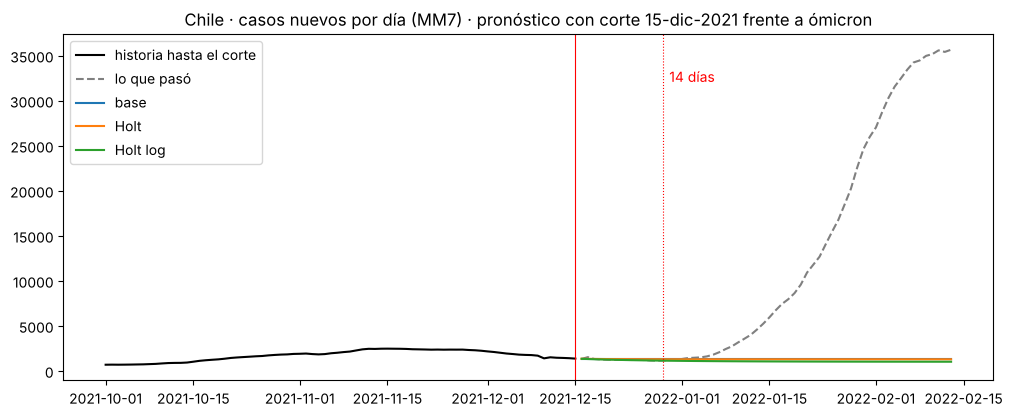

Pico real (MM7): 35,656 el 2022-02-13 · base: 1,369 · Holt al día 60: 1,295 · Holt log al día 60: 1,022


In [29]:
# Lo mismo, pero mirando más lejos: corte el 15-dic-2021 y horizonte hasta el pico (60 días)
corte = "2021-12-15"
largo = pronosticar("Chile", corte, horizonte=60)
real = chile.reindex(largo["fecha"])

fig, eje = plt.subplots(figsize=(12, 4.5))
eje.plot(chile["2021-10-01":corte].index, chile["2021-10-01":corte], color="black", label="historia hasta el corte")
eje.plot(real.index, real, color="gray", linestyle="--", label="lo que pasó")
eje.plot(largo["fecha"], largo["base"], color="tab:blue", label="base")
eje.plot(largo["fecha"], largo["holt"], color="tab:orange", label="Holt")
eje.plot(largo["fecha"], largo["holt_log"], color="tab:green", label="Holt log")
eje.axvline(pd.Timestamp(corte), color="red", linewidth=0.8)
eje.axvline(pd.Timestamp(corte) + pd.Timedelta(days=14), color="red", linewidth=0.8, linestyle=":")
eje.text(pd.Timestamp(corte) + pd.Timedelta(days=15), real.max() * 0.9, "14 días", color="red")
eje.set_title("Chile · casos nuevos por día (MM7) · pronóstico con corte 15-dic-2021 frente a ómicron")
eje.legend(loc="upper left")
plt.show()
print("Pico real (MM7):", f"{real.max():,.0f}", "el", real.idxmax().date(),
      "· base:", f"{largo['base'].iloc[0]:,.0f}", "· Holt al día 60:", f"{largo['holt'].iloc[-1]:,.0f}",
      "· Holt log al día 60:", f"{largo['holt_log'].iloc[-1]:,.0f}")

In [30]:
# 2 y 3 · Primera alerta desde el 15-nov-2021 en Chile y en países donde ómicron llegó antes
paises_omicron = ["South Africa", "United Kingdom", "US", "Argentina", "Brazil", "Chile"]
fechas_omicron = pd.date_range("2021-11-15", "2022-01-31")
filas = []
for pais in paises_omicron:
    dias = pd.DataFrame([alerta(pais, fecha) for fecha in fechas_omicron])
    primera = dias[dias["activa"]].iloc[0]     # primer día con la alerta activa
    filas.append({"país": pais, "primera alerta": primera["fecha"].date(),
                  "incidencia ese día": primera["incidencia_100k"],
                  "variación semanal ese día (%)": primera["variacion_semanal_pct"]})
primeras = pd.DataFrame(filas).set_index("país")
primeras["días antes del inicio en Chile (10-ene-2022)"] = (pd.Timestamp("2022-01-10") - pd.to_datetime(primeras["primera alerta"])).dt.days
primeras.round(1)

,primera alerta,incidencia ese día,variación semanal ese día (%),días antes del inicio en Chile (10-ene-2022)
país,,,,
South Africa,2021-11-23,5.4,1003.5,48
United Kingdom,2021-12-16,92.5,31.2,25
US,2021-11-18,28.8,29.4,53
Argentina,2021-12-11,5.5,26.6,30
Brazil,2022-01-05,5.5,96.1,5
Chile,2022-01-03,7.7,26.2,7


### Respuesta P6
- **Con el pronóstico, no.** Con corte el 15-dic-2021 los tres modelos aciertan los 14 días siguientes (MAPE 11,4 % base,
  7,3 % Holt y 2,2 % Holt log), porque esas dos semanas siguieron tranquilas. Pero proyectan entre 1.000 y 1.400 casos por día
  y el pico fue de **35.656 el 13-feb-2022, más de 25 veces más**. Con corte el 31-dic-2021 la ola ya empezaba y los tres se quedan
  cortos (día 14: 5.242 reales contra ≈ 1.300; MAPE ≈ 40 %). Un modelo que solo mira la curva de Chile no puede ver una variante nueva.
- **Con la alerta de Chile, una semana.** Se activó el **3-ene-2022** (7,7 por 100.000, +26 % en la semana): 7 días antes de que
  empezara la ola y **41 días antes del pico**. Alcanza para preparar camas y turnos, no para evitar la ola.
- **Con la alerta de otros países, entre 3 y 7 semanas.** Con los mismos datos del DW y la misma `alerta`:
  **Sudáfrica** se activó el **23-nov-2021** con una subida de **+1.003 % en una semana** (48 días antes del inicio de la ola en Chile; ahí se
  informó ómicron por primera vez); **Argentina** el 11-dic (30 días antes) y **Reino Unido** el 16-dic (25 días antes).
  La alerta de EE.UU. del 18-nov no se cuenta: es anterior a su primer caso de ómicron (1-dic-2021), o sea, la ola de Delta.
- **Conclusión:** la ola de ómicron **sí se podía anticipar**, pero no pronosticando la serie de Chile, sino **vigilando a otros
  países**: una subida brusca en un país donde aparece una variante nueva es la señal temprana. Insumo para una
  recomendación al Comité (R8).